Part 2

Get predictions on evaluation set

In [20]:
import numpy as np
from scipy.special import softmax

pred_output = trainer.predict(eval_dataset)

logits = pred_output.predictions
labels = pred_output.label_ids

probs = softmax(logits, axis=1)[:, 1]

# Use your chosen threshold (0.3)
threshold = 0.3
preds = (probs >= threshold).astype(int)

Convert eval_dataset back to DataFrame

In [21]:
eval_df = eval_dataset.to_pandas()

eval_df["label"] = labels
eval_df["pred"] = preds
eval_df["prob"] = probs

Create cohorts

In [22]:
# High-black cohort
high_black = eval_df[eval_df["black"] >= 0.5]

# Reference cohort (white, not black)
reference = eval_df[(eval_df["black"] < 0.1) & (eval_df["white"] >= 0.5)]

print("High-black cohort size:", len(high_black))
print("Reference cohort size:", len(reference))

High-black cohort size: 170
Reference cohort size: 202


Define metric function

In [23]:
from sklearn.metrics import confusion_matrix

def compute_metrics(df):
    y_true = df["label"]
    y_pred = df["pred"]

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    TPR = tp / (tp + fn) if (tp + fn) > 0 else 0
    FPR = fp / (fp + tn) if (fp + tn) > 0 else 0
    FNR = fn / (fn + tp) if (fn + tp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    return {
        "TPR": TPR,
        "FPR": FPR,
        "FNR": FNR,
        "Precision": precision,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

Compute metrics for both cohorts

In [24]:
metrics_black = compute_metrics(high_black)
metrics_ref = compute_metrics(reference)

print("High-black metrics:", metrics_black)
print("Reference metrics:", metrics_ref)

High-black metrics: {'TPR': np.float64(0.6190476190476191), 'FPR': np.float64(0.08411214953271028), 'FNR': np.float64(0.38095238095238093), 'Precision': np.float64(0.8125), 'TN': np.int64(98), 'FP': np.int64(9), 'FN': np.int64(24), 'TP': np.int64(39)}
Reference metrics: {'TPR': np.float64(0.38596491228070173), 'FPR': np.float64(0.06896551724137931), 'FNR': np.float64(0.6140350877192983), 'Precision': np.float64(0.6875), 'TN': np.int64(135), 'FP': np.int64(10), 'FN': np.int64(35), 'TP': np.int64(22)}


Disparate Impact Ratio

In [25]:
disparate_impact = metrics_black["FPR"] / metrics_ref["FPR"]

print("Disparate Impact (FPR ratio):", disparate_impact)

Disparate Impact (FPR ratio): 1.219626168224299


Summary Table

In [26]:
import pandas as pd

summary = pd.DataFrame([
    ["High-Black", metrics_black["TPR"], metrics_black["FPR"], metrics_black["FNR"], metrics_black["Precision"]],
    ["Reference", metrics_ref["TPR"], metrics_ref["FPR"], metrics_ref["FNR"], metrics_ref["Precision"]],
], columns=["Group", "TPR", "FPR", "FNR", "Precision"])

print(summary)

        Group       TPR       FPR       FNR  Precision
0  High-Black  0.619048  0.084112  0.380952     0.8125
1   Reference  0.385965  0.068966  0.614035     0.6875


Bar Chart (TPR, FPR, FNR)

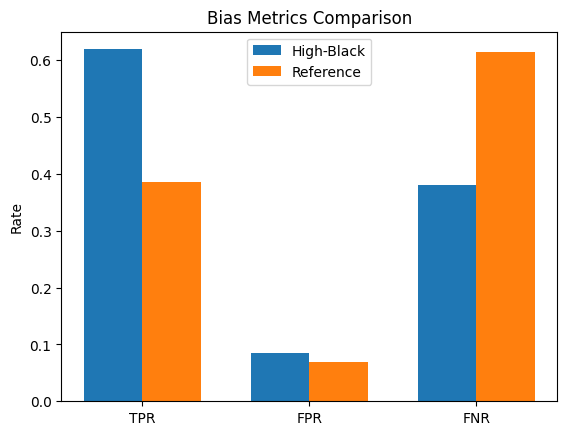

In [27]:
import matplotlib.pyplot as plt

labels_plot = ["TPR", "FPR", "FNR"]

black_vals = [metrics_black["TPR"], metrics_black["FPR"], metrics_black["FNR"]]
ref_vals = [metrics_ref["TPR"], metrics_ref["FPR"], metrics_ref["FNR"]]

x = np.arange(len(labels_plot))
width = 0.35

plt.figure()
plt.bar(x - width/2, black_vals, width, label="High-Black")
plt.bar(x + width/2, ref_vals, width, label="Reference")

plt.xticks(x, labels_plot)
plt.ylabel("Rate")
plt.title("Bias Metrics Comparison")
plt.legend()
plt.show()

Confusion Matrices

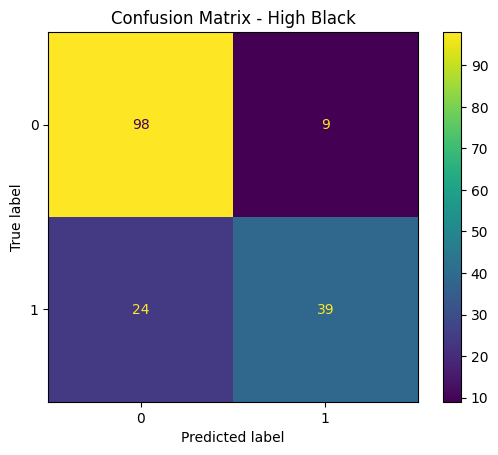

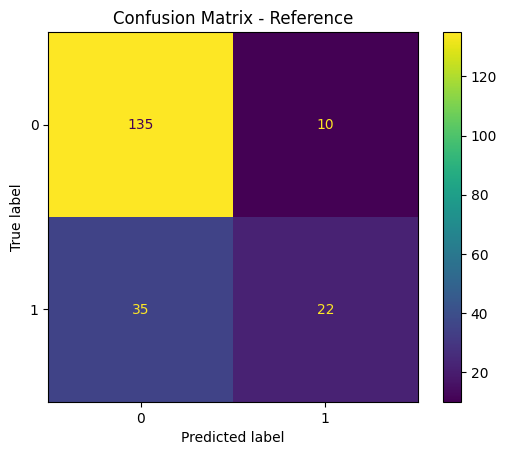

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

# High-black
ConfusionMatrixDisplay.from_predictions(
    high_black["label"], high_black["pred"]
)
plt.title("Confusion Matrix - High Black")
plt.show()

# Reference
ConfusionMatrixDisplay.from_predictions(
    reference["label"], reference["pred"]
)
plt.title("Confusion Matrix - Reference")
plt.show()

In [34]:
aif_df = eval_df[["label", "pred"]].copy()

# Create protected attribute (group)
aif_df["group"] = (eval_df["black"] >= 0.5).astype(int)


In [35]:
from aif360.datasets import BinaryLabelDataset

dataset = BinaryLabelDataset(
    df=aif_df,
    label_names=["label"],
    protected_attribute_names=["group"]
)

In [37]:
pred_dataset = dataset.copy()
pred_dataset.labels = aif_df["pred"].values.reshape(-1, 1)

In [38]:
from aif360.metrics import ClassificationMetric

metric = ClassificationMetric(
    dataset,
    pred_dataset,
    unprivileged_groups=[{"group": 1}],  # high-black
    privileged_groups=[{"group": 0}]     # others
)

print("Statistical Parity Difference:", metric.statistical_parity_difference())
print("Equal Opportunity Difference:", metric.equal_opportunity_difference())

Statistical Parity Difference: 0.2222419981608377
Equal Opportunity Difference: 0.0474330357142857


Bias Analysis and Key Findings

The largest disparity is observed in the True Positive Rate (TPR) and False Negative Rate (FNR) between the two cohorts.

High-Black cohort TPR = 0.619
Reference cohort TPR = 0.386

This shows a large gap, meaning the model detects toxic content much more effectively in the High-Black cohort.

Similarly:

High-Black FNR = 0.381
Reference FNR = 0.614

This indicates the model misses significantly more toxic comments in the Reference cohort.

Over-flagging vs Under-flagging

The model shows both over-flagging and differential detection behavior:

Over-flagging (FPR):
The High-Black cohort has a higher FPR (0.084 vs 0.069), meaning more non-toxic comments are incorrectly flagged. This indicates the model is stricter toward this group.
Under-flagging (FNR):
The Reference cohort has a much higher FNR (0.614), meaning many toxic comments are not detected in this group.

Overall, the model is more aggressive on the High-Black cohort and more lenient on the Reference cohort.

Real-World Consequences
For High-Black cohort:
Higher chance of having non-toxic content flagged (false positives)
Potential suppression of legitimate speech
Can lead to perceived or actual discrimination and loss of trust in the platform
For Reference cohort:
Higher chance of toxic content being missed (false negatives)
Harmful content may remain visible longer
Reduced effectiveness of moderation for this group
Final Conclusion

The model does not behave uniformly across groups. It tends to over-flag the High-Black cohort while under-flagging the Reference cohort, leading to both fairness concerns and uneven moderation quality across users.